<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Linear Algebra 2: Collinearity

In [ ]:
#titanic linear regression
import pandas as pd
import numpy as np

# I downloaded the data in a zip file and uploaded to this colab manually
df = pd.read_csv('/content/train.csv')

'''
description
# Dependent variable (y): Fare --> the passenger fare paid
# Independent variables (X): chosen as Pclass, Age, SibSp
# Pclass: ticket class (1st, 2nd, 3rd) --> proxy for cabin quality/location
# Age: passenger age
# SibSp: number of siblings/spouses aboard --> proxy for family size/group booking
'''

# dropping NaN values
model_df = df[['Fare', 'Pclass', 'Age', 'SibSp']].dropna()

# matrix X and target vector y
y = model_df['Fare'].values.reshape(-1, 1) # shape (n, 1)
X_raw = model_df[['Pclass', 'Age', 'SibSp']].values # shape (n, 3)
n = X_raw.shape[0]

# Add a column of ones to X_raw to account for the intercept term (beta_0)
# model: Fare = b0*1 + b1*Pclass + b2*Age + b3*SibSp
intercept_col = np.ones((n, 1))
X = np.hstack([intercept_col, X_raw]) # shape (n, 4)

# Solving the normal equations: beta = (X^T X)^-1 X^T y
XtX = X.T @ X
XtX_inv = np.linalg.inv(XtX)
XtY = X.T @ y
beta = XtX_inv @ XtY  # shape (4, 1): [intercept, b_Pclass, b_Age, b_SibSp]

print("Estimated coefficients (beta):")
print(f"Intercept (b0):        {beta[0][0]:.4f}")
print(f"Pclass coefficient:    {beta[1][0]:.4f}")
print(f"Age coefficient:       {beta[2][0]:.4f}")
print(f"SibSp coefficient:     {beta[3][0]:.4f}")

# predictions and residuals calculation
y_hat = X @ beta
residuals = y - y_hat

# R^2 calculation to check model fit
ss_res = np.sum(residuals ** 2)
ss_tot = np.sum((y - np.mean(y)) ** 2)
r_squared = 1 - (ss_res / ss_tot)
print(f"\nR-squared: {r_squared:.4f}")

# Cross-check against sklearn's LinearRegression for validation
from sklearn.linear_model import LinearRegression

sklearn_model = LinearRegression()
sklearn_model.fit(X_raw, y.ravel())

print("\nsklearn coefficients (should match beta[1:] above):")
print(f"Intercept: {sklearn_model.intercept_:.4f}")
print(f"Coefficients: {sklearn_model.coef_}")

Estimated coefficients (beta):
Intercept (b0):        121.8853
Pclass coefficient:    -37.3874
Age coefficient:       -0.2725
SibSp coefficient:     8.8276

R-squared: 0.3425

sklearn coefficients (should match beta[1:] above):
Intercept: 121.8853
Coefficients: [-37.38743244  -0.27245257   8.82761655]


Fitted coefficients:
Intercept: 121.8853, Pclass: -37.3874, Age: -0.2725, SibSp: 8.8276


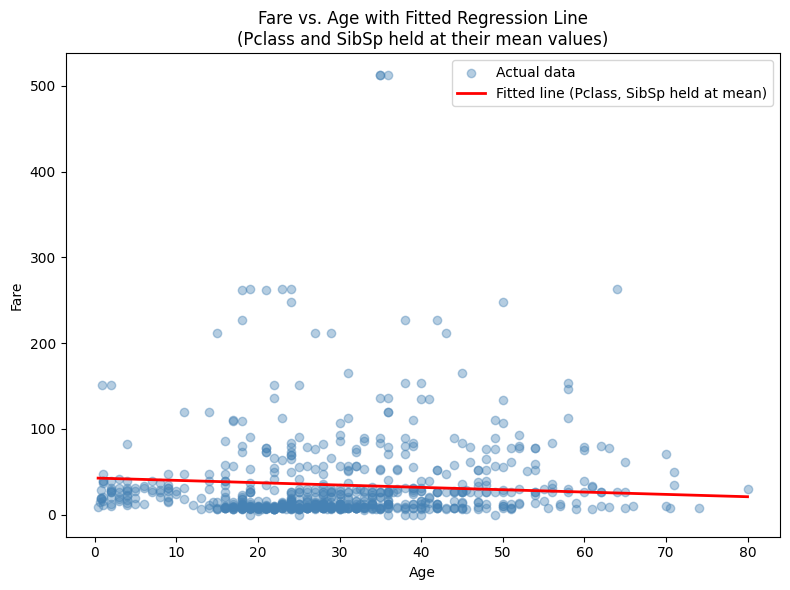

In [ ]:
# I manually wrote my code
# and corrected multiple errors using Claude
# there are much lesser errors than before, I am improving!

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
# noqa: F401 (needed for 3D projection registration)

# Dependent variable: Fare
# Independent variables: Pclass, Age, SibSp
model_df = df[['Fare', 'Pclass', 'Age', 'SibSp']].dropna()

y = model_df['Fare'].values.reshape(-1, 1)
X_raw = model_df[['Pclass', 'Age', 'SibSp']].values
n = X_raw.shape[0]

# intercept column for the full (n x 4) regression fit
intercept_col = np.ones((n, 1))
X = np.hstack([intercept_col, X_raw])

# solving normal equations for the full dataset fit
# beta = (X^T X)^-1 X^T y
beta = np.linalg.inv(X.T @ X) @ (X.T @ y)
b0, b1, b2, b3 = beta.flatten()  # intercept, Pclass, Age, SibSp coefficients

print("Fitted coefficients:")
print(f"Intercept: {b0:.4f}, Pclass: {b1:.4f}, Age: {b2:.4f}, SibSp: {b3:.4f}")

'''
PLOT 1: 2D projection of Fare vs. Age, holding other variables fixed
Since there are 3 predictors, we can't plot the full model in 2D directly.
Instead, we project: pick one variable (Age) for the x-axis, plot actual
data as a scatter, then overlay the fitted line by holding Pclass and
SibSp fixed at their mean values (a common technique for visualizing
one slice of a multivariate hyperplane).
'''
fig, ax = plt.subplots(figsize=(8, 6))

# scatter plot of actual data: Age vs Fare
ax.scatter(model_df['Age'], model_df['Fare'], alpha=0.4, label='Actual data', color='steelblue')

# a line across the range of Age, holding Pclass and SibSp at their means
age_range = np.linspace(model_df['Age'].min(), model_df['Age'].max(), 100)
pclass_mean = model_df['Pclass'].mean()
sibsp_mean = model_df['SibSp'].mean()

# predicted fare along this slice:
# Fare_hat = b0 + b1*Pclass_mean + b2*Age + b3*SibSp_mean
fare_pred_line = b0 + b1 * pclass_mean + b2 * age_range + b3 * sibsp_mean

ax.plot(age_range, fare_pred_line, color='red', linewidth=2,
        label=f'Fitted line (Pclass, SibSp held at mean)')
ax.set_xlabel('Age')
ax.set_ylabel('Fare')
ax.set_title('Fare vs. Age with Fitted Regression Line\n(Pclass and SibSp held at their mean values)')
ax.legend()
plt.tight_layout()
plt.savefig('fare_vs_age_fit.png', dpi=150)
plt.show()


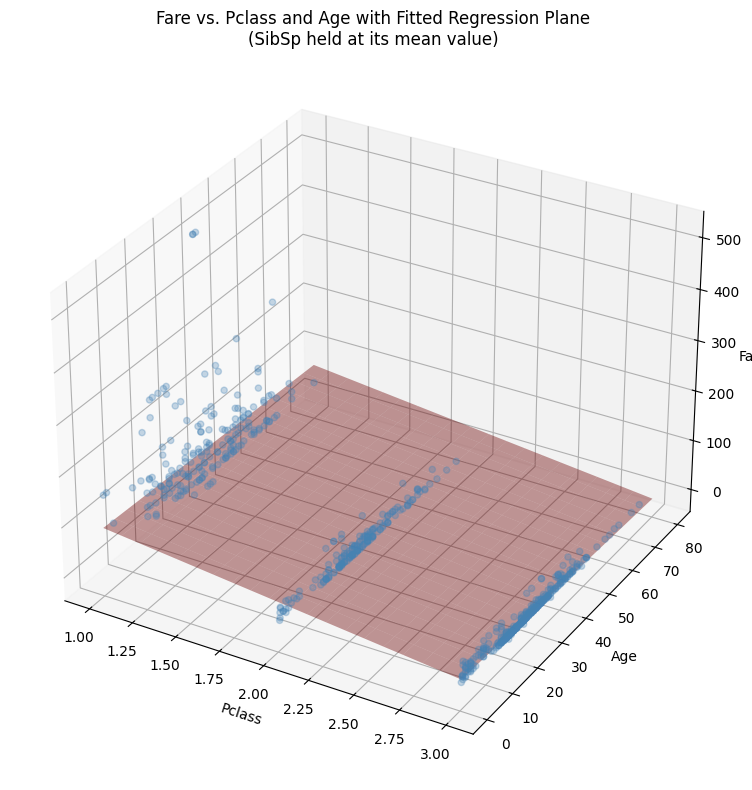

In [ ]:
'''
PLOT 2: 3D scatter plot for Fare vs. Pclass and Age with plane fit
Here, we have two predictors on the horizontal axes,
Fare on the vertical axis and,
the fitted plane is plotted as a surface.
'''
fig2 = plt.figure(figsize=(10, 8))
ax2 = fig2.add_subplot(111, projection='3d')

# Scatter plot of actual data points
ax2.scatter(model_df['Pclass'], model_df['Age'], model_df['Fare'],
            alpha=0.3, color='steelblue', label='Actual data')

# a meshgrid over Pclass and Age to draw the fitted plane
pclass_grid = np.linspace(model_df['Pclass'].min(), model_df['Pclass'].max(), 20)
age_grid = np.linspace(model_df['Age'].min(), model_df['Age'].max(), 20)
pclass_mesh, age_mesh = np.meshgrid(pclass_grid, age_grid)

# Fare_hat = b0 + b1*Pclass + b2*Age + b3*SibSp_mean
# SibSp held at mean since we can't plot 4 dimensions at once,
# this is a 2-predictor slice of the full model
fare_mesh = b0 + b1 * pclass_mesh + b2 * age_mesh + b3 * sibsp_mean

ax2.plot_surface(pclass_mesh, age_mesh, fare_mesh, alpha=0.4, color='red')
ax2.set_xlabel('Pclass')
ax2.set_ylabel('Age')
ax2.set_zlabel('Fare')
ax2.set_title('Fare vs. Pclass and Age with Fitted Regression Plane\n(SibSp held at its mean value)')
plt.tight_layout()
plt.savefig('fare_3d_plane_fit.png', dpi=150)
plt.show()


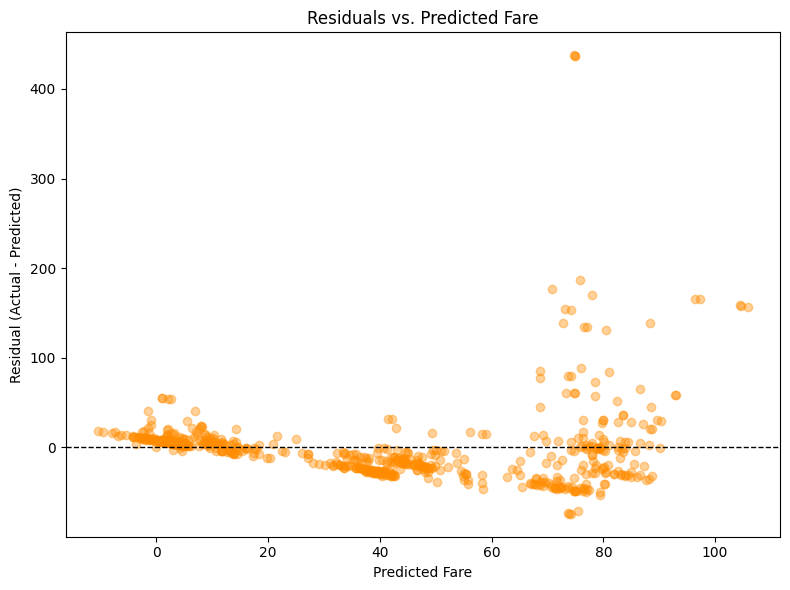

In [ ]:
'''
PLOT 3: Residuals plot as a sanity check
Plotting predicted fare vs. residuals will help us visually confirm whether
the "random scatter around the hyperplane" assumption from the theory
actually holds, or whether there's a pattern (which would violate the
model's assumptions about the error term).
'''

y_hat_full = X @ beta
residuals_full = y - y_hat_full

fig3, ax3 = plt.subplots(figsize=(8, 6))
ax3.scatter(y_hat_full, residuals_full, alpha=0.4, color='darkorange')
ax3.axhline(0, color='black', linestyle='--', linewidth=1)
ax3.set_xlabel('Predicted Fare')
ax3.set_ylabel('Residual (Actual - Predicted)')
ax3.set_title('Residuals vs. Predicted Fare')
plt.tight_layout()
plt.savefig('residuals_plot.png', dpi=150)
plt.show()

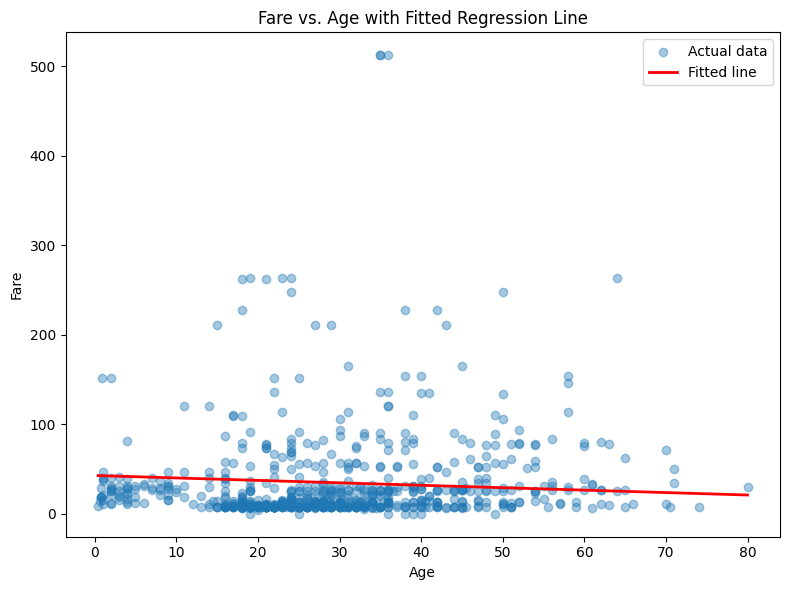

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

'''
2D visualization plot of Fare vs. Age,
overlaying the fitted line with Pclass and SibSp held at their mean values.
We are showing a "slice" of a multiple variable hyperplan
in 2D since we cannot plot 4 dimensions at once.
'''
age_range = np.linspace(model_df['Age'].min(), model_df['Age'].max(), 100)
fare_pred_line = b0 + b1 * model_df['Pclass'].mean() + b2 * age_range + b3 * model_df['SibSp'].mean()

plt.figure(figsize=(8, 6))
plt.scatter(model_df['Age'], model_df['Fare'], alpha=0.4, label='Actual data')
plt.plot(age_range, fare_pred_line, color='red', linewidth=2, label='Fitted line')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.title('Fare vs. Age with Fitted Regression Line')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# SSR for the full dataset, using the beta already fit via normal equations
y_hat_full = X @ beta
residuals_full = y - y_hat_full
ssr = np.sum(residuals_full ** 2)

print(f"Sum of Squared Residuals (SSR): {ssr:.4f}")

Sum of Squared Residuals (SSR): 1312882.8386


In [ ]:
# Sum of Absolute Residuals for the full dataset
y_hat_full = X @ beta
residuals_full = y - y_hat_full
sad = np.sum(np.abs(residuals_full))

print(f"Sum of Absolute Residuals (SAD): {sad:.4f}")

Sum of Absolute Residuals (SAD): 15535.8215
